In [11]:
import pandas as pd 
import numpy as np 

In [12]:
data_raw=pd.read_csv('vectors_in_orbit.csv')
data_raw.drop(columns=['Unnamed: 0'],inplace=True)
data=data_raw.copy()

In [13]:
data['Product Subcategory'].value_counts().count()

np.int64(920)

In [14]:
data['Product Subcategory'].value_counts().describe()

count    920.000000
mean      46.119565
std       17.116729
min        5.000000
25%       46.000000
50%       48.000000
75%       48.000000
max      146.000000
Name: count, dtype: float64

In [15]:
data['Total Ratings'].describe()

count     42430.000000
mean       7098.745934
std       18140.191465
min           1.000000
25%         311.000000
50%        1542.000000
75%        6077.000000
max      633890.000000
Name: Total Ratings, dtype: float64

In [16]:
data.head()

,Product ID,Product Category,Product Subcategory,Product Name,Product URL,Product Price ($),Product Rating,Total Ratings,Product Image
0,0,Electronics,Smartphones,"SAMSUNG Galaxy S25 Ultra Cell Phone, 512GB AI ...",https://www.amazon.com/SAMSUNG-Smartphone-Unlo...,1219.99,4.3,247,https://m.media-amazon.com/images/I/61n0lmxP5-...
1,1,Electronics,Smartphones,"SAMSUNG Galaxy A16 5G A Series Cell Phone, Unl...",https://www.amazon.com/SAMSUNG-Unlocked-Smartp...,174.99,4.2,166,https://m.media-amazon.com/images/I/71KGkQ+KOK...
2,2,Electronics,Smartphones,Tracfone | Motorola Moto g Play 2024 | Locked ...,https://www.amazon.com/Tracfone-Motorola-5000m...,39.88,4.3,428,https://m.media-amazon.com/images/I/71CxUvG46r...
3,3,Electronics,Smartphones,"SAMSUNG Galaxy S24 FE AI Phone, 128GB Unlocked...",https://www.amazon.com/SAMSUNG-Unlocked-Smartp...,498.95,4.5,567,https://m.media-amazon.com/images/I/61uakkLoHx...
4,4,Electronics,Smartphones,Moto G 5G | 2024 | Unlocked | Made for US 4/12...,https://www.amazon.com/Moto-Unlocked-128GB-Cam...,149.99,4.2,1677,https://m.media-amazon.com/images/I/71Sbx9zQN3...


In [17]:
max_=data['Total Ratings'].agg('max')
data[data['Total Ratings']==max_]

,Product ID,Product Category,Product Subcategory,Product Name,Product URL,Product Price ($),Product Rating,Total Ratings,Product Image
902,941,Books,Novels,Where the Crawdads Sing: Reese's Book Club,https://www.amazon.com/Where-Crawdads-Sing-Del...,9.41,4.7,633890,https://m.media-amazon.com/images/I/81lbmz5t2s...


### $\text{bayes\_rating} = \frac{v}{v+m}R + \frac{m}{v+m}C$

 ***Bayesian/Wilson-style adjusted score is a way to avoid over-ranking items that have a high average rating but very few reviews . It replaces the raw average with a “confidence-aware” estimate.***
 

### $\text{value\_score} = \frac{\text{bayes\_rating}\cdot \log(1+v)}{\text{price}}$

***This stays simple to explain and directly supports “cheap but reliable” ranking***

In [18]:
data.iloc[0]

Product ID                                                             0
Product Category                                             Electronics
Product Subcategory                                          Smartphones
Product Name           SAMSUNG Galaxy S25 Ultra Cell Phone, 512GB AI ...
Product URL            https://www.amazon.com/SAMSUNG-Smartphone-Unlo...
Product Price ($)                                                1219.99
Product Rating                                                       4.3
Total Ratings                                                        247
Product Image          https://m.media-amazon.com/images/I/61n0lmxP5-...
Name: 0, dtype: object

In [19]:
R= data.groupby('Product Subcategory')['Product Rating'].agg('mean')  
v=data.groupby('Product Subcategory')['Total Ratings'].agg('sum')  
C=data['Product Rating'].agg('mean') 
R

Product Subcategory
3D printers         4.168750
Acoustic panels     4.250000
Acrylic paints      4.656842
Action Figures      4.608696
Action figures      4.602222
                      ...   
Wrenches            4.608333
Xbox controllers    4.206250
Xylophones          4.489130
Yarn                4.608333
Yoga mats           4.452083
Name: Product Rating, Length: 920, dtype: float64

In [22]:
C=mean([data['Product Rating'][i] for i in data.index])  #global mean rating
m=data['Product Price ($)'].agg('median') # prior strength (50th percentile for moderate smoothing) 


In [23]:
from statistics import mean
def bayes_rating (i,C,m):
    R=data['Product Rating'][i]  #average rating (0–5)
    v=data['Total Ratings'][i]  # total ratings
    b_r=v/(v+m)*R + m/(v+m)*C
    return b_r 
bayes_rating=[ bayes_rating(i,C,m) for i in data.index]

In [24]:
len(bayes_rating)

42430

In [30]:
min(bayes_rating),max(bayes_rating)

(np.float64(2.505329525701912), np.float64(4.990139850343389))

***==> smartphones bayes rating is 4.19***

In [32]:
from math import log

value_score=[
    bayes_rating[i]*log(1+data['Total Ratings'][i])/data.iloc[i]['Product Price ($)'] 
    for i in data.index ]

In [33]:
value_score[0]

np.float64(0.019504779862584618)

In [36]:
data['Product Bayes_rating']=bayes_rating
data['Product Value_score']=value_score

In [34]:
min(value_score),max(value_score)

(np.float64(7.623699957422563e-05), np.float64(1974.837597430471))

In [38]:
data.loc[data["Product Value_score"].idxmax(), ["Product Name","Product Subcategory","Product Price ($)","Total Ratings","Product Rating","Product Bayes_rating","Product Value_score"]]


Product Name                      iLH
Product Subcategory     Diamond rings
Product Price ($)                0.01
Total Ratings                     182
Product Rating                    3.7
Product Bayes_rating         3.790849
Product Value_score       1974.837597
Name: 39099, dtype: object

In [40]:
data[data['Product Subcategory']=='Diamond rings']

,Product ID,Product Category,Product Subcategory,Product Name,Product URL,Product Price ($),Product Rating,Total Ratings,Product Image,Product Bayes_rating,Product Value_score
39069,40170,Jewelry,Diamond rings,Amazon Essentials,https://www.amazon.com/sspa/click?ie=UTF8&spc=...,583.40,5.0,3,https://m.media-amazon.com/images/I/61FyXKVC9I...,4.537866,0.010783
39070,40171,Jewelry,Diamond rings,Houston Diamond District,https://www.amazon.com/sspa/click?ie=UTF8&spc=...,577.15,4.7,82,https://m.media-amazon.com/images/I/51f4WK5PxC...,4.650222,0.035604
39071,40172,Jewelry,Diamond rings,Houston Diamond District,https://www.amazon.com/sspa/click?ie=UTF8&spc=...,534.06,4.7,60,https://m.media-amazon.com/images/I/71Ob9Csb3f...,4.637183,0.035694
39072,40173,Jewelry,Diamond rings,GLAM AND GEMS,https://www.amazon.com/sspa/click?ie=UTF8&spc=...,600.00,4.8,13,https://m.media-amazon.com/images/I/51bPNbJ4FQ...,4.592512,0.020200
39073,40174,Jewelry,Diamond rings,Houston Diamond District,https://www.amazon.com/14K-Solitaire-CERTIFIED...,1699.15,4.8,40,https://m.media-amazon.com/images/I/61ujzJvaKS...,4.680060,0.010228
39074,40176,Jewelry,Diamond rings,PAVOI,https://www.amazon.com/PAVOI-Sterling-Zirconia...,17.95,4.4,25895,https://m.media-amazon.com/images/I/61t6JF-TZR...,4.400074,2.490967
39075,40177,Jewelry,Diamond rings,THELANDA,https://www.amazon.com/4-Prong-Twisted-Simulat...,279.99,4.6,1000,https://m.media-amazon.com/images/I/61r2Ryz-tf...,4.597190,0.113436
39076,40178,Jewelry,Diamond rings,IMOLOVE,https://www.amazon.com/IMOLOE-Diamond-Wedding-...,99.00,4.9,15,https://m.media-amazon.com/images/I/61vDe+S2Y7...,4.641626,0.129993
39077,40179,Jewelry,Diamond rings,PAVOI,https://www.amazon.com/PAVOI-White-Plated-Zirc...,15.95,4.1,5577,https://m.media-amazon.com/images/I/71i2Y+1BPc...,4.101628,2.218373
39078,40180,Jewelry,Diamond rings,Houston Diamond District,https://www.amazon.com/sspa/click?ie=UTF8&spc=...,882.97,4.5,14,https://m.media-amazon.com/images/I/71aeAL3+JS...,4.487418,0.013763


In [42]:
data.groupby('Product Subcategory')['Product Price ($)'].describe()

,count,mean,std,min,25%,50%,75%,max
Product Subcategory,,,,,,,,
3D printers,16.0,347.365625,330.125203,179.00,207.4900,254.565,259.0000,1529.00
Acoustic panels,48.0,62.610208,46.601429,11.89,30.2900,41.240,91.1900,169.99
Acrylic paints,95.0,26.081895,16.265973,0.99,13.4900,24.980,35.0750,86.31
Action Figures,46.0,23.937174,12.429033,4.99,14.9900,24.150,30.7400,68.86
Action figures,45.0,23.701111,12.587360,4.99,14.9900,23.090,30.9900,68.86
...,...,...,...,...,...,...,...,...
Wrenches,48.0,63.481250,106.602789,7.64,20.5275,33.430,55.4900,699.00
Xbox controllers,16.0,78.098125,57.027592,22.99,39.4075,46.645,119.2425,199.99
Xylophones,46.0,42.741739,58.182924,6.39,13.1400,23.140,41.4900,269.99


In [45]:
PRICE = "Product Price ($)"
SUB   = "Product Subcategory"

q30 = data.groupby(SUB)[PRICE].transform(lambda s: s.quantile(0.30))
q70 = data.groupby(SUB)[PRICE].transform(lambda s: s.quantile(0.70))

data["price_bucket"] = np.select(
    [data[PRICE] <= q30, data[PRICE] <= q70],
    ["cheap", "mid"],
    default="premium"
)

In [48]:
data.tail(50)

,Product ID,Product Category,Product Subcategory,Product Name,Product URL,Product Price ($),Product Rating,Total Ratings,Product Image,Product Bayes_rating,Product Value_score,price_bucket
42380,43540,Tools & Home Improvement,Tool storage,VELCRO Brand Easy Hang Extension Cord Holder O...,https://www.amazon.com/VELCRO-Brand-Extension-...,10.86,4.7,1365,https://m.media-amazon.com/images/I/81fTUF+mz0...,4.696202,3.121998,cheap
42381,43541,Tools & Home Improvement,Tool storage,Spacecare Power Tool Organizer- Power Drill To...,https://www.amazon.com/Spacecare-Organizer-Hol...,23.99,4.5,843,https://m.media-amazon.com/images/I/71-+IW+sTG...,4.499449,1.263775,cheap
42382,43542,Tools & Home Improvement,Tool storage,"DWVO 5x3ft Outdoor Storage Shed, Weatherproof ...",https://www.amazon.com/DWVO-Weatherproof-Venti...,129.99,4.1,53,https://m.media-amazon.com/images/I/819wMi9SrT...,4.218431,0.129450,premium
42383,43543,Tools & Home Improvement,Tool storage,"3 Tier Rolling Utility Cart with Drawer,REBECA...",https://www.amazon.com/Rolling-REBECAT-Multifu...,22.39,4.4,1127,https://m.media-amazon.com/images/I/51bic60C6T...,4.401669,1.381680,cheap
42384,43544,Tools & Home Improvement,Tool storage,Akro-Mils 24-Drawer Plastic Drawer Storage Cab...,https://www.amazon.com/Akro-Mils-10124-Plastic...,42.79,4.5,51840,https://m.media-amazon.com/images/I/61JkQYh0xD...,4.499991,1.141660,mid
42385,43545,Tools & Home Improvement,Tool storage,Klein Tools 54823MB MODbox 3-Drawer Tool Box O...,https://www.amazon.com/Klein-Tools-54823MB-3-D...,235.14,5.0,52,https://m.media-amazon.com/images/I/51dwBuSHT+...,4.835860,0.081653,premium
42386,43546,Tools & Home Improvement,Tool storage,KAFAHOM Power Tool Organizer-8 Drill Holder Wa...,https://www.amazon.com/KAFAHOM-Organizer-8-Sto...,53.54,4.5,1216,https://m.media-amazon.com/images/I/81mbMpmiFA...,4.499615,0.597047,mid
42387,43547,Tools & Home Improvement,Tool storage,keomaisyto Garden Tool Organizer for Garage Or...,https://www.amazon.com/keomaisyto-Organizer-Or...,42.49,4.7,17,https://m.media-amazon.com/images/I/71DtrGednz...,4.571286,0.310961,mid
42388,43548,Tools & Home Improvement,Tool storage,"KAFAHOM Power Tool Organizer, 8 Drill Holder W...",https://www.amazon.com/KAFAHOM-Organizer-Organ...,53.82,4.5,1178,https://m.media-amazon.com/images/I/81wRxczINn...,4.499602,0.591287,mid
42389,43549,Tools & Home Improvement,Tool storage,"CRAFTSMAN Storage Organizer, 30 Small Drawer M...",https://www.amazon.com/Craftsman-CMST40730-SMA...,20.98,4.7,2178,https://m.media-amazon.com/images/I/61J-xqGVLN...,4.697604,1.721101,cheap


<Axes: xlabel='Product Value_score', ylabel='Product Bayes_rating'>

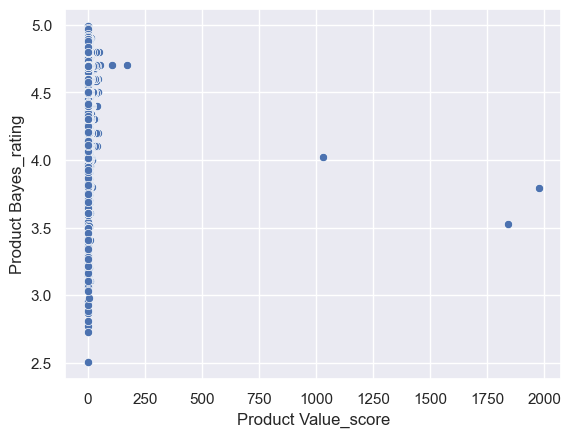

In [51]:
import seaborn as sns 
sns.set()

sns.scatterplot(x=data['Product Value_score'],y=data['Product Bayes_rating'],data=data)

In [58]:
data[data['Product Value_score']>75]

,Product ID,Product Category,Product Subcategory,Product Name,Product URL,Product Price ($),Product Rating,Total Ratings,Product Image,Product Bayes_rating,Product Value_score,price_bucket
18615,19288,Groceries,Noodles,"Maruchan Instant Lunch, Chicken, 2.25 oz",https://www.amazon.com/Maruchan-Instant-Lunch-...,0.39,4.7,7426,https://m.media-amazon.com/images/I/61am6N7gC1...,4.699292,107.395413,cheap
18710,19384,Groceries,Instant soups,"Maruchan Instant Lunch, Chicken, 2.25 oz",https://www.amazon.com/Maruchan-Instant-Lunch-...,0.39,4.7,7426,https://m.media-amazon.com/images/I/61am6N7gC1...,4.699292,107.395413,cheap
19188,19865,Groceries,Organic groceries,Organic Banana,https://www.amazon.com/Fresh-Produce-Brands-Va...,0.28,4.7,24982,https://m.media-amazon.com/images/I/31oubF6Sde...,4.699789,169.963688,cheap
34465,35483,Music,Music software,Sony Sound Forge Audio Studio 10- 30 Day Free ...,https://www.amazon.com/Sony-Sound-Forge-Studio...,0.01,3.4,183,https://m.media-amazon.com/images/I/81Eo-qBWQ6...,3.525180,1838.358726,cheap
39099,40203,Jewelry,Diamond rings,iLH,https://www.amazon.com/Diamond-Zircon-Engageme...,0.01,3.7,182,https://m.media-amazon.com/images/I/71WLNS9aFT...,3.790849,1974.837597,cheap
39110,40214,Jewelry,Diamond rings,Washranp,https://www.amazon.com/Exquisite-Marquise-Zirc...,0.01,3.1,12,https://m.media-amazon.com/images/I/71tIl5QXab...,4.019922,1031.089753,cheap


In [53]:
data_=data[data['Product Value_score']<1000]

<Axes: xlabel='Product Value_score', ylabel='Product Bayes_rating'>

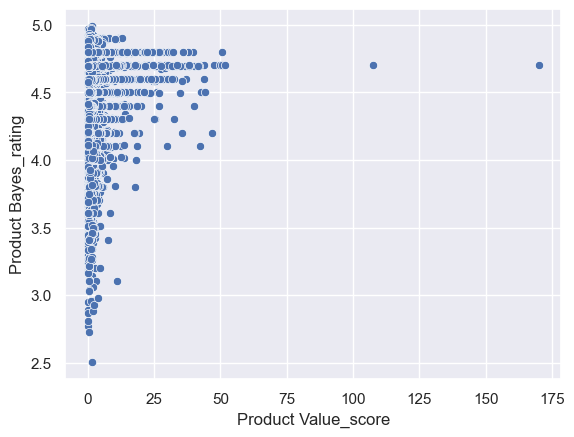

In [54]:
sns.scatterplot(x=data_['Product Value_score'],y=data_['Product Bayes_rating'],data=data_)

In [59]:
data_.columns

Index(['Product ID', 'Product Category', 'Product Subcategory', 'Product Name',
       'Product URL', 'Product Price ($)', 'Product Rating', 'Total Ratings',
       'Product Image', 'Product Bayes_rating', 'Product Value_score',
       'price_bucket'],
      dtype='object')

In [60]:
data_=data_[['Product ID', 'Product Category', 'Product Subcategory','price_bucket', 'Product Name',
        'Product Price ($)', 'Product Rating', 'Total Ratings',
        'Product Bayes_rating', 'Product Value_score',
        'Product Image']]
data_.head()

,Product ID,Product Category,Product Subcategory,price_bucket,Product Name,Product Price ($),Product Rating,Total Ratings,Product Bayes_rating,Product Value_score,Product Image
0,0,Electronics,Smartphones,premium,"SAMSUNG Galaxy S25 Ultra Cell Phone, 512GB AI ...",1219.99,4.3,247,4.315942,0.019505,https://m.media-amazon.com/images/I/61n0lmxP5-...
1,1,Electronics,Smartphones,mid,"SAMSUNG Galaxy A16 5G A Series Cell Phone, Unl...",174.99,4.2,166,4.235365,0.123873,https://m.media-amazon.com/images/I/71KGkQ+KOK...
2,2,Electronics,Smartphones,cheap,Tracfone | Motorola Moto g Play 2024 | Locked ...,39.88,4.3,428,4.309558,0.655020,https://m.media-amazon.com/images/I/71CxUvG46r...
3,3,Electronics,Smartphones,premium,"SAMSUNG Galaxy S24 FE AI Phone, 128GB Unlocked...",498.95,4.5,567,4.499191,0.057189,https://m.media-amazon.com/images/I/61uakkLoHx...
4,4,Electronics,Smartphones,mid,Moto G 5G | 2024 | Unlocked | Made for US 4/12...,149.99,4.2,1677,4.203950,0.208119,https://m.media-amazon.com/images/I/71Sbx9zQN3...


In [64]:
data_['Product Category'].value_counts()

Product Category
Furniture                   2795
Toys                        2749
Kitchenware                 2443
Beauty & Personal           1723
Groceries                   1480
Home Decor                  1480
Baby Products               1457
Healthcare & Wellness       1448
Footwear                    1440
Office Supplies             1436
Beauty & Personal Care      1432
Pet Supplies                1419
Art & Craft                 1418
Jewelry                     1378
Arts & Crafts               1336
Health & Household          1324
Music Instruments           1318
Art Supplies                1294
Gardening & Outdoor         1293
Travel Accessories          1263
Sports & Outdoors           1261
Automotive                  1234
Tools & Home Improvement    1232
Books                       1227
Camping & Hiking            1156
Music                       1120
Industrial & Scientific     1012
Electronics                  856
Gaming & Accessories         714
Home Appliances           

In [66]:
data_.columns

Index(['Product ID', 'Product Category', 'Product Subcategory', 'price_bucket',
       'Product Name', 'Product Price ($)', 'Product Rating', 'Total Ratings',
       'Product Bayes_rating', 'Product Value_score', 'Product Image'],
      dtype='object')

In [62]:
data_.to_csv('vio_EDA.csv')